In [1]:
# standard libraries
import os, sys, json, time, glob
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import clear_output
from skimage.metrics import peak_signal_noise_ratio as psnr
from datetime import datetime
import copy

# your project modules (run from the ambient_flow_MRI folder)
sys.path.append(os.getcwd())
from model.model import build_unet, UNetVelocity
from loss.loss import ambient_loss, ambient_loss_with_plot
from data.data import BrainAmbientFlowMatchingDataset
from util.helper import *

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [7]:
N_COILS = 16
DELTA, EPS, LR = 0.1, 1e-3, 1e-4
BATCH_SIZE = 4
MAX_STEPS, print_every, train_every, val_every, ckpt_every = 100, 500, 50, 50, 2000
save_path = "/egr/research-slim/luozishe/MSM-MRI/ambient_flow_MRI/run"; os.makedirs(save_path, exist_ok=True)
ckpt_dir = "/egr/research-slim/luozishe/MSM-MRI/ambient_flow_MRI/ckpt_ambient_fm"; os.makedirs(ckpt_dir, exist_ok=True)

In [8]:
split_index = json.load(open("/egr/research-slim/luozishe/MSM-MRI/ambient_flow_MRI/split_16x320x320.json"))

train_set = BrainAmbientFlowMatchingDataset(index=split_index["train"], accel=4, cf=0.08)
val_set   = BrainAmbientFlowMatchingDataset(index=split_index["val"],   accel=4, cf=0.08)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                                           num_workers=4, pin_memory=True, drop_last=True)
val_loader = torch.utils.data.DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)


In [9]:
model = build_unet(n_coils=N_COILS).to(device)
optim = torch.optim.AdamW(model.parameters(), lr=LR)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

25.3M parameters


torch.Size([1, 16, 320, 320]) torch.Size([1, 1, 1, 320])


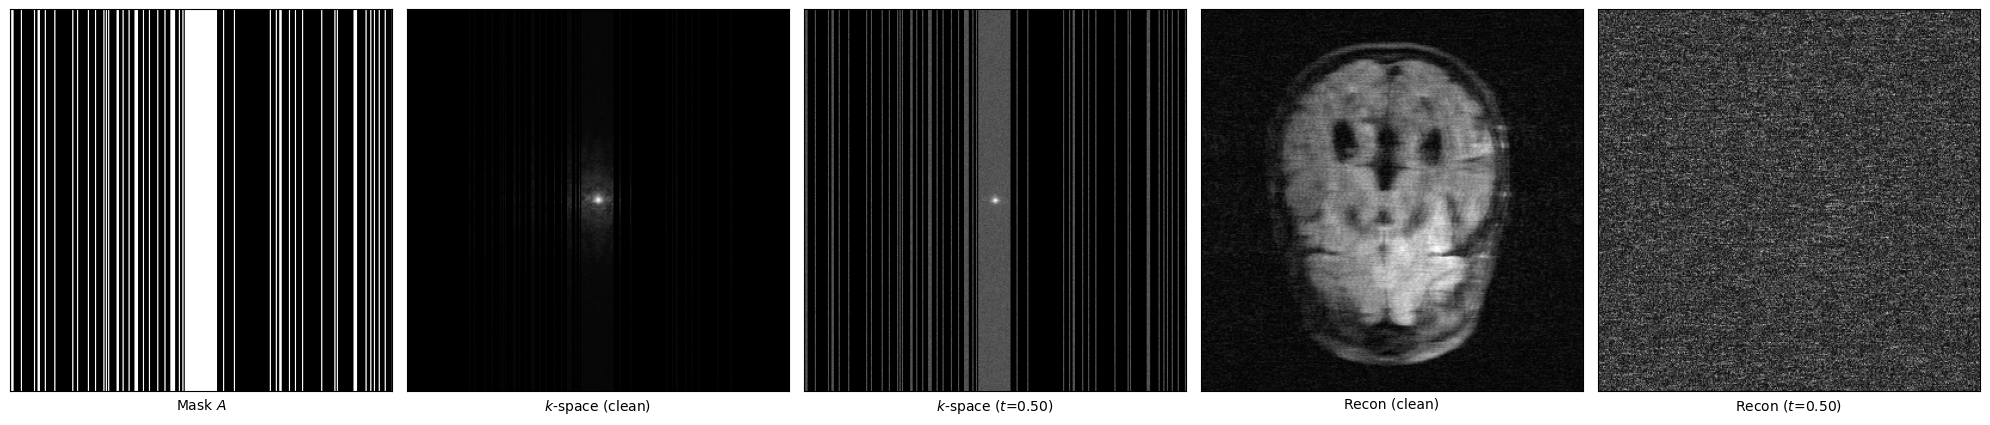

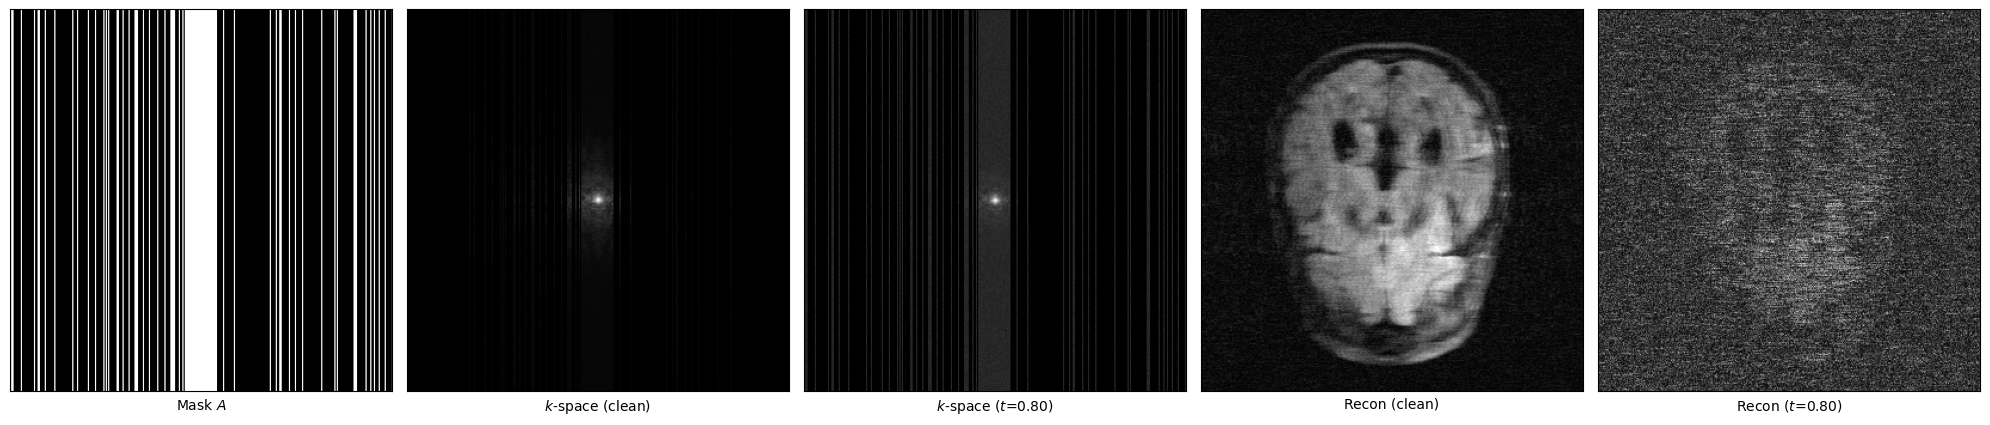

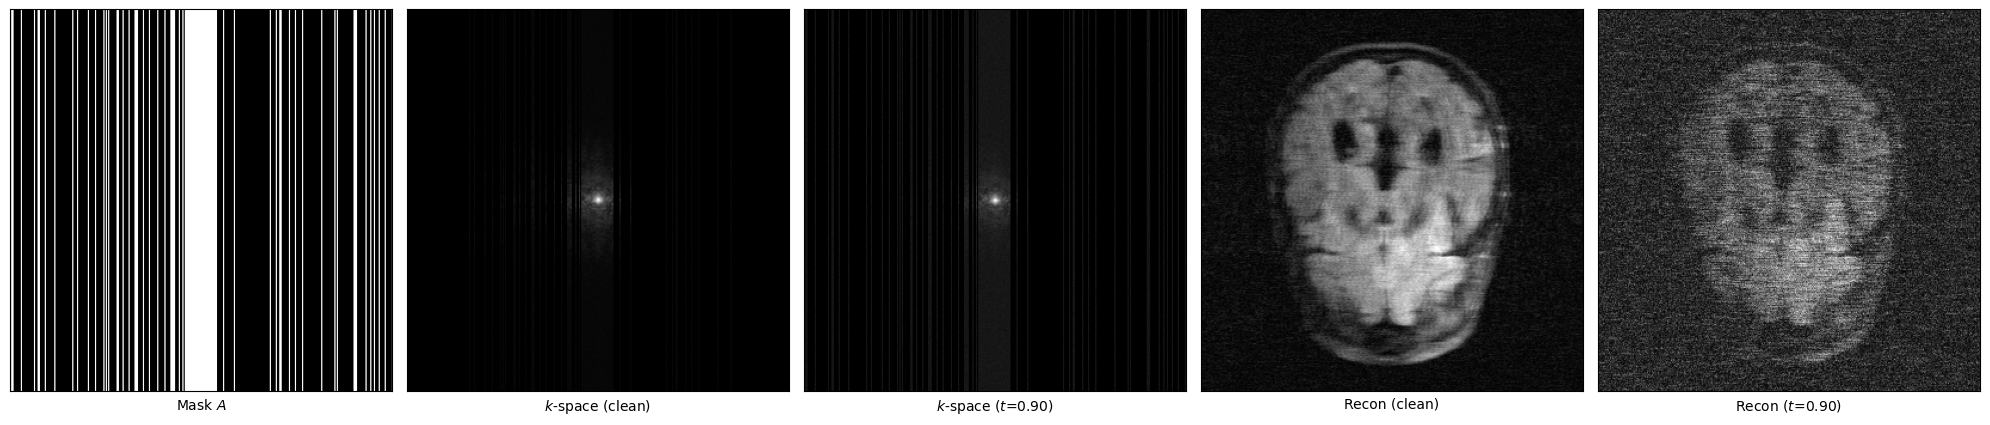

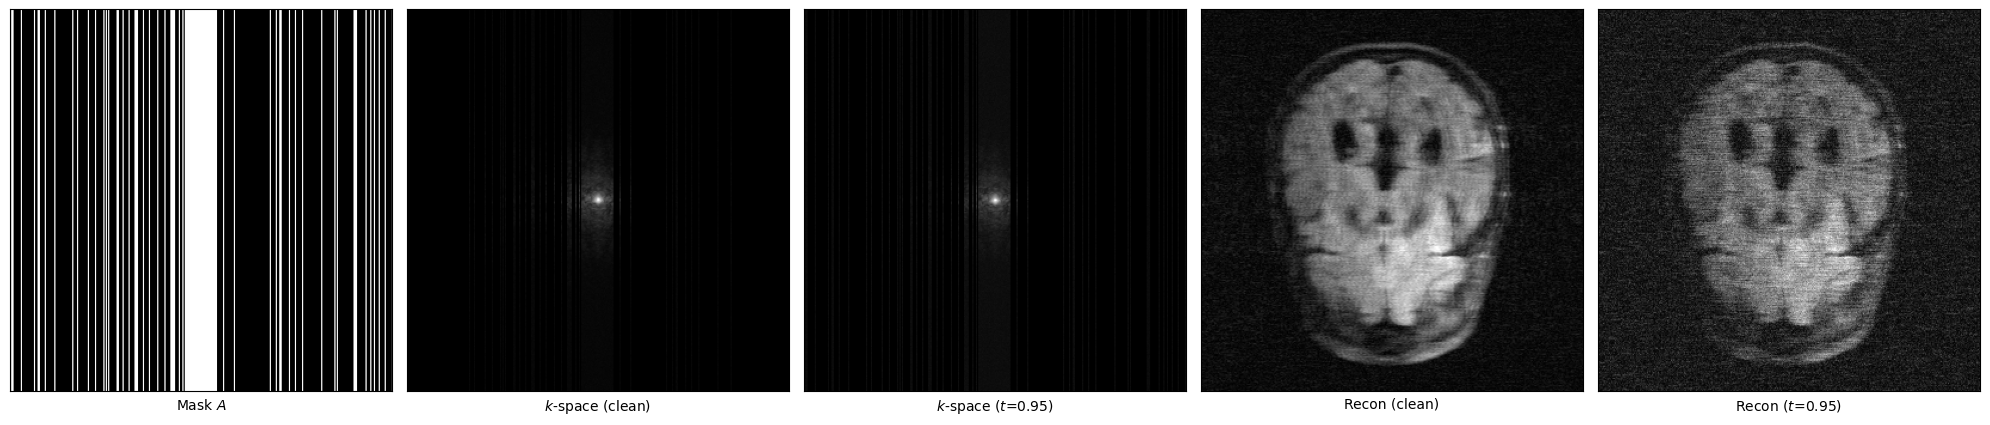

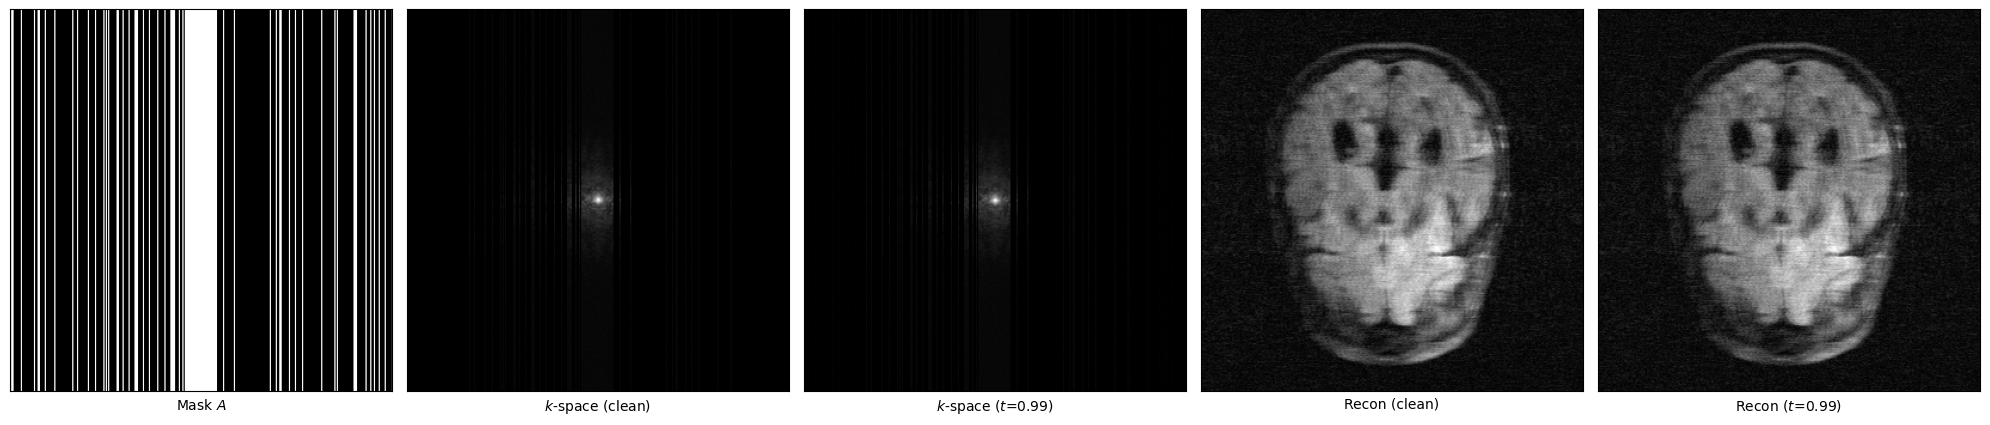

In [10]:
fix_y, fix_A, _ = val_set[80]                 # one slice: (16, 320, 320), (1, 1, 320)
fix_y, fix_A = fix_y[None], fix_A[None]      # (1, 16, 320, 320), (1, 1, 1, 320)
print(fix_y.shape, fix_A.shape)
# plot_recon(model, fix_y, fix_A, t0=EPS)
for t0 in [0.5, 0.8, 0.9, 0.95, 0.99]:
    plot_image(fix_y, fix_A, t=t0)

Step 1:


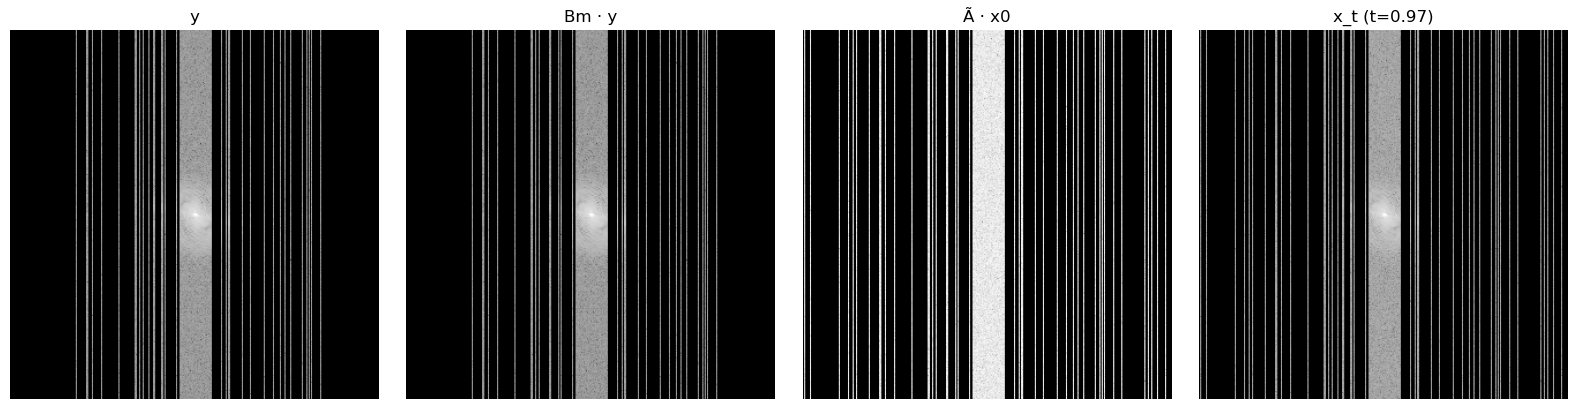

loss = 1.7868   baseline = 0.9489   ratio = 1.883
Step 1:


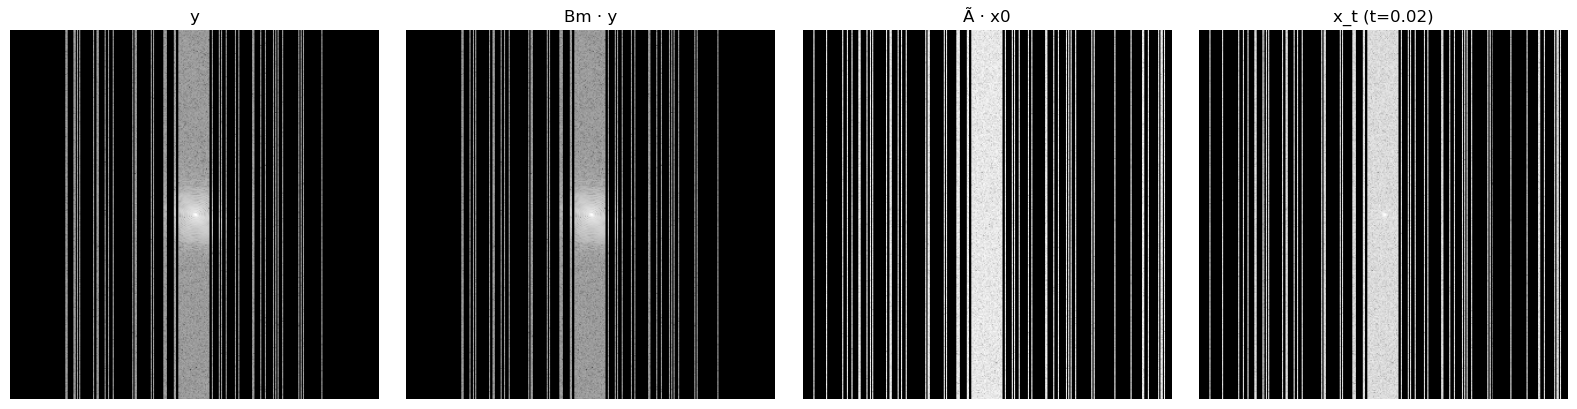

loss = 1.5336   baseline = 0.9468   ratio = 1.620
Step 1:


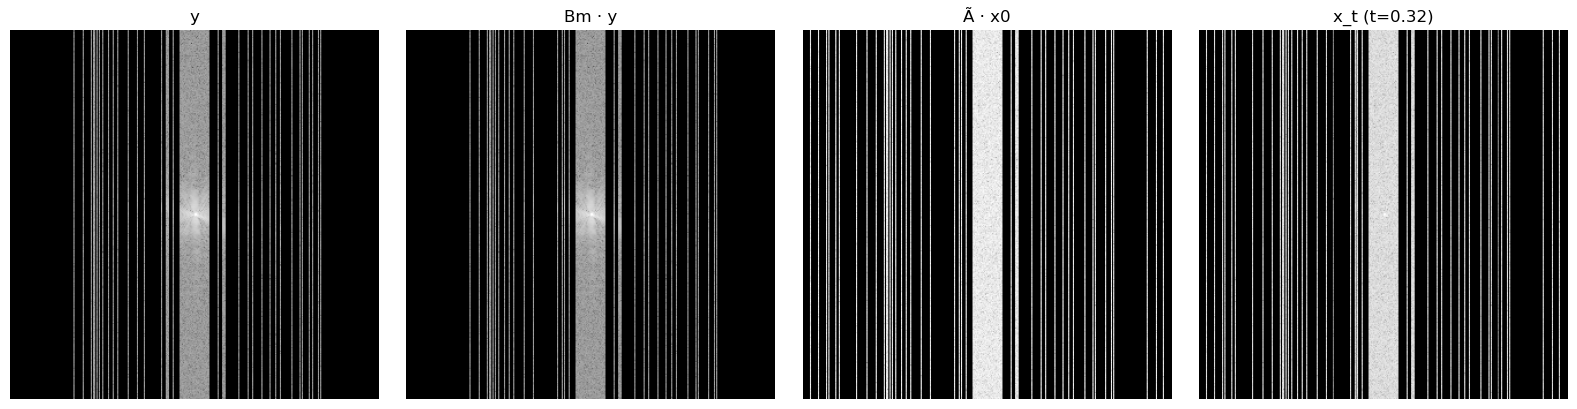

loss = 1.3518   baseline = 0.9273   ratio = 1.458
Step 1:


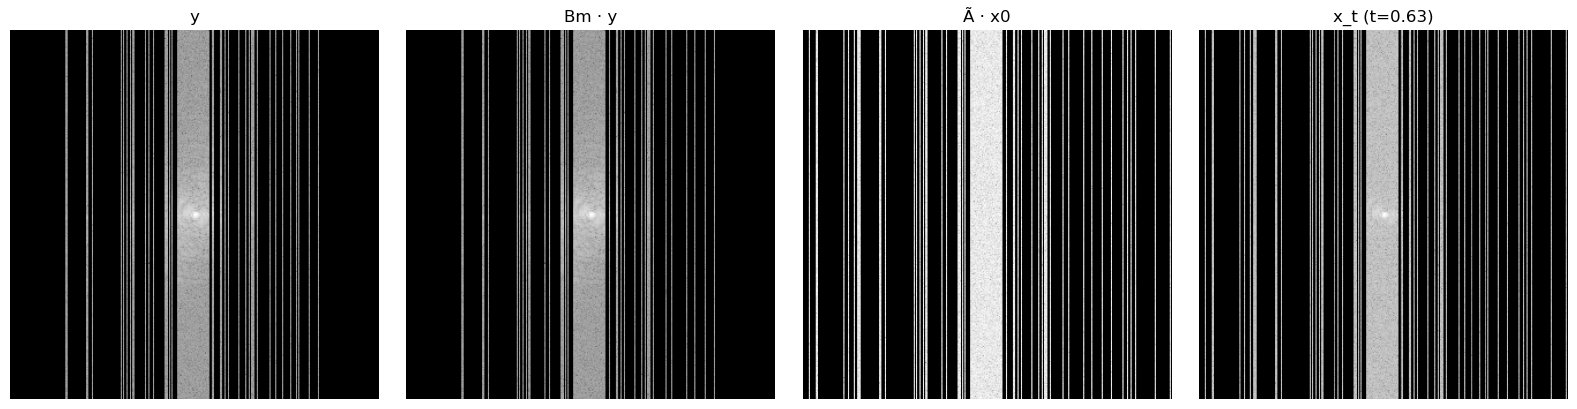

loss = 1.2629   baseline = 0.9467   ratio = 1.334
Step 1:


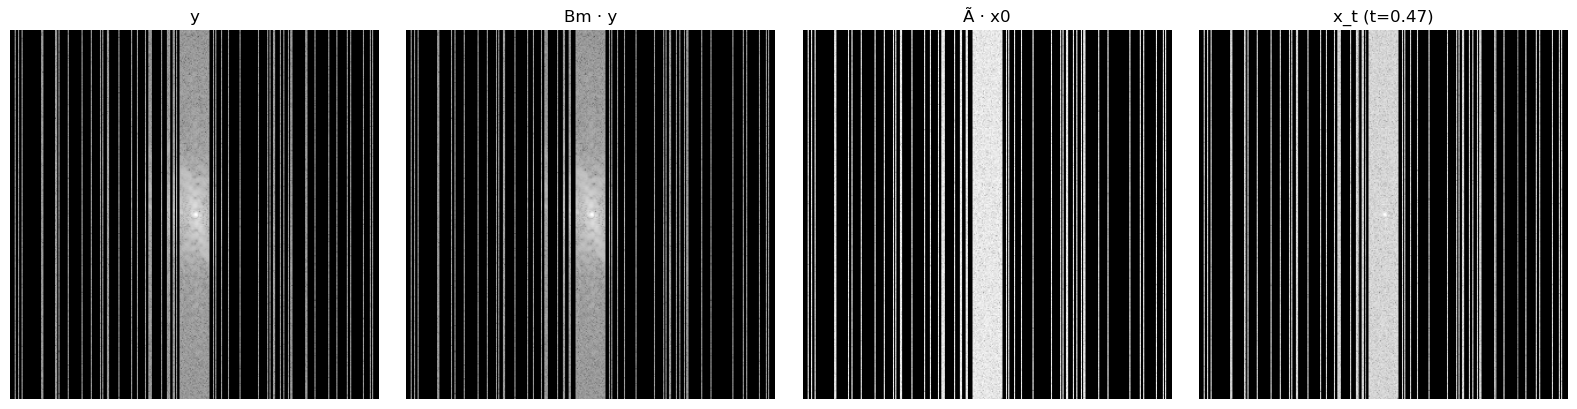

loss = 1.1727   baseline = 0.9277   ratio = 1.264
Step 1:


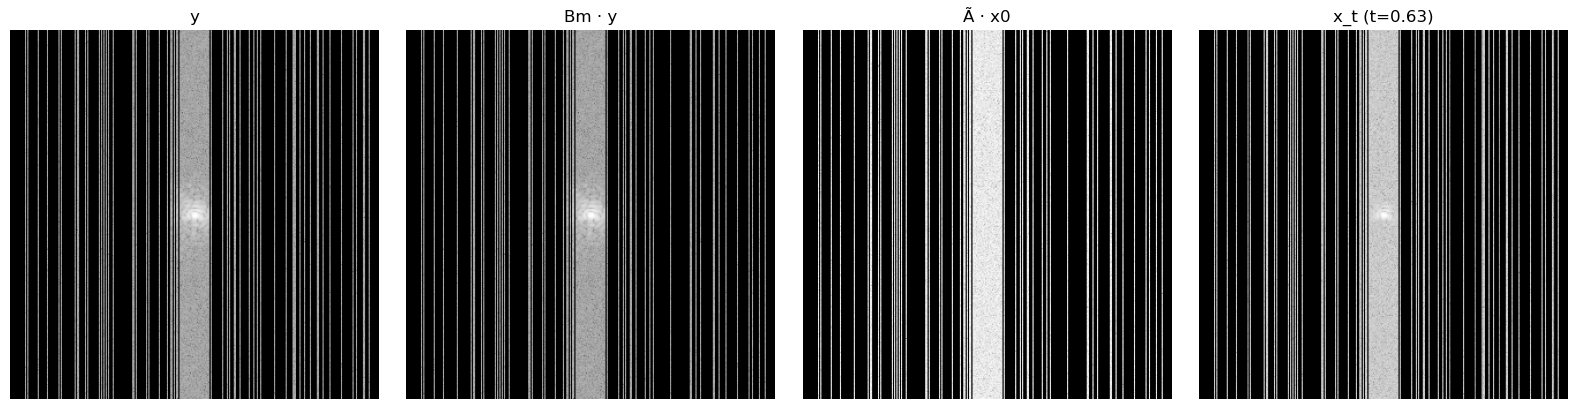

loss = 1.1017   baseline = 0.9162   ratio = 1.202
Step 1:


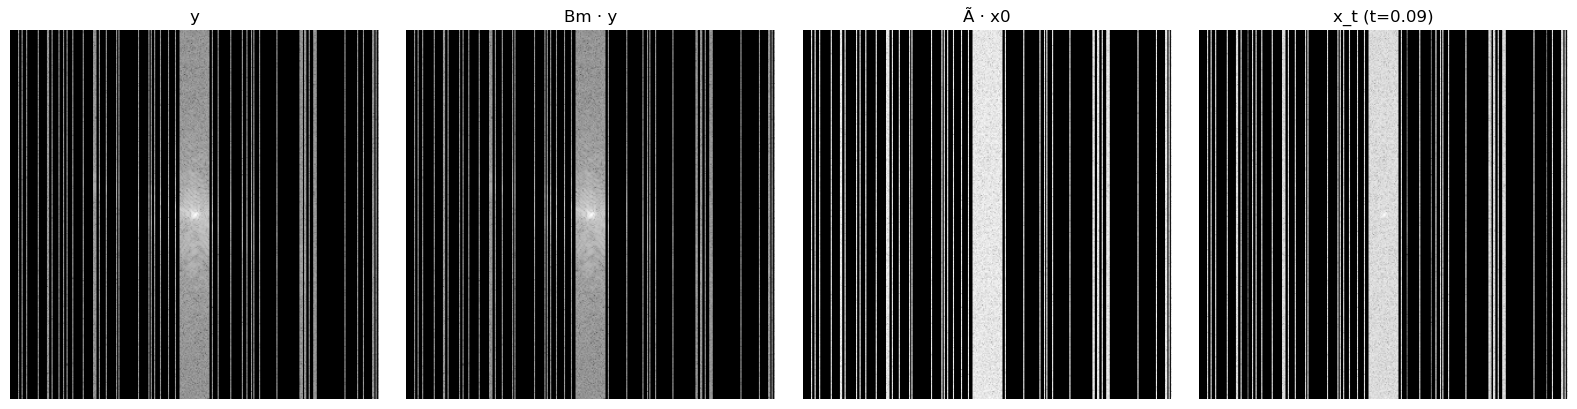

loss = 1.0765   baseline = 0.9321   ratio = 1.155
Step 1:


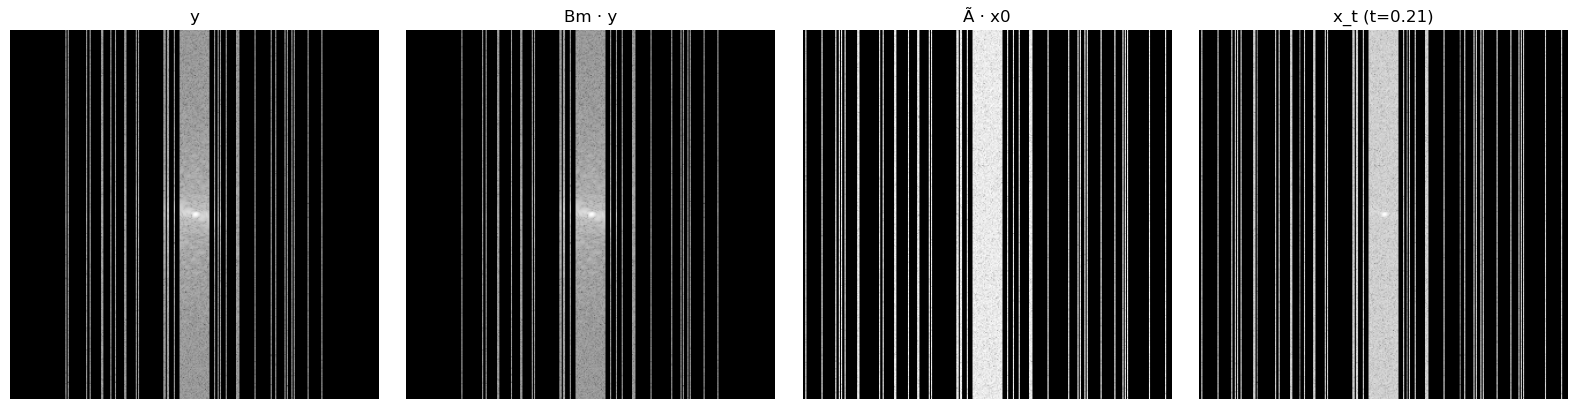

In [ ]:
train_losses, train_psnr, val_losses, val_psnr, train_steps, val_steps = [], [], [], [], [], []
start_time = time.time()
best_val, best_state, best_step = float("inf"), None, 0

for i in range(MAX_STEPS):

    for y, A, _ in train_loader:
        
        print(f"Step {i+1}:")
        train_loss = ambient_loss_with_plot(model, y, A, delta=DELTA, eps=EPS)

        optim.zero_grad(set_to_none=True)
        train_loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optim.step()

        if (i + 1) % val_every == 0:
            for vy, vA, _ in val_loader:
                with torch.no_grad():
                    model.eval()
                    val_loss = ambient_loss_with_plot(model, vy, vA, delta=DELTA, eps=EPS).item()
                    val_losses.append(val_loss)
                    model.train()
                val_steps.append(i + 1)

            if val_loss < best_val:                                     # best checkpoint so far
                best_val, best_state, best_step = val_loss, copy.deepcopy(model.state_dict()), i + 1
    
    train_losses.append(train_loss.item())
    train_steps.append(i + 1)
    
    # if (i + 1) % print_every == 0:
    #     elapsed = time.time() - start_time
    #     clear_output(wait=True)
    #     print(f"| iter {i+1:6d} | {elapsed * 1000 / print_every:7.1f} ms/step | "
    #           f"train {np.mean(train_losses[-print_every:]):.4f} | "
    #           f"val {val_losses[-1] if val_losses else float('nan'):.4f}")

In [ ]:
run_dir = os.path.join(save_path, datetime.now().strftime("%Y%m%d_%H%M%S"))
os.makedirs(run_dir, exist_ok=True)

plt.figure(figsize=(6, 4))
plt.semilogy(train_steps, train_losses, alpha=0.4, label="train")
if val_losses: plt.semilogy(val_steps, val_losses, "o-", label="val")
plt.xlabel("step"); plt.ylabel("loss"); plt.title("Loss"); plt.legend(); plt.tight_layout()
plt.savefig(f"{run_dir}/loss.png", dpi=150); plt.close()

# PSNR: train vs. validation
plt.figure(figsize=(6, 4))
if train_psnr: plt.plot(train_steps, train_psnr, alpha=0.6, label="train")
if val_psnr:   plt.plot(val_steps, val_psnr, "o-", label="val")
plt.xlabel("step"); plt.ylabel("PSNR (dB)"); plt.title("PSNR"); plt.legend(); plt.tight_layout()
plt.savefig(f"{run_dir}/psnr.png", dpi=150); plt.close()

print("saved:", os.listdir(run_dir))

torch.save({"model": best_state, "best_val": best_val, "best_step": best_step}, f"{run_dir}/best.pt")
print("best checkpoint saved:", f"{run_dir}/best.pt")
